# Data Slayer 4.0 Baseline Notebook

Objective: Mengklasifikasikan setiap sequence video ujian (30 frame, 1 detik) menjadi normal (0) atau cheat (1) dengan F1-Macro sebagai metrik evaluasi.

Pendekatan baseline: video train dipotong menjadi klip 30 frame agar formatnya sama dengan test, lalu setiap klip diubah menjadi fitur gerakan (frame difference dan optical flow) serta fitur pose kasar (HOG). Model LightGBM dilatih dengan validasi GroupKFold per subjek. Tidak memakai pretrained weights atau data eksternal.

# Sinkronisasi versi modules dan libraries

In [1]:
import sys; print(sys.version)
%pip install -q --no-warn-script-location \
    numpy==2.4.4 pandas==2.3.3 scikit-learn==1.8.0 lightgbm==4.6.0 matplotlib==3.10.9 joblib==1.5.3 opencv-python-headless==5.0.0.93

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Import modules dan libraries

In [2]:
import os, glob, random, time
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix
from lightgbm import LGBMClassifier
cv2.setNumThreads(1)

### Random state
Menetapkan satu konstanta SEED untuk semua bagian yang memakai randomness agar hasil prediksi bisa dibuat ulang oleh panitia.

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
print("SEED =", SEED)

SEED = 42


# Import datasets

In [4]:
_DATA_DIR_CANDIDATES = [
    "../data", "data", "../../data",
    *glob.glob("/kaggle/input/*"), *glob.glob("/kaggle/input/**/", recursive=True),
]
DATA_DIR = next((d for d in _DATA_DIR_CANDIDATES if d and os.path.exists(os.path.join(d, "sample_submission.csv"))), None)
if DATA_DIR is None:
    raise FileNotFoundError("sample_submission.csv not found in any candidate DATA_DIR - set it manually.")
print("DATA_DIR =", os.path.abspath(DATA_DIR))

CACHE_DIR = "cache/baseline"
for _d in (CACHE_DIR, "models", "submissions"):
    os.makedirs(_d, exist_ok=True)

sample_sub = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

DATA_DIR = D:\Lomba\Data Science\data-slayer\dataslayer\data


### Index video train
Nama file train berformat `train/{cheat|normal}/subject_{i}/{front|side}_{Behavior}.MOV`, jadi label, subjek, angle, dan perilaku bisa diambil dari path.

In [5]:
def parse_train_path(path):
    parts = os.path.normpath(path).split(os.sep)
    category, subject, fname = parts[-3], parts[-2], parts[-1]
    angle, behavior = os.path.splitext(fname)[0].split("_", 1)
    return dict(path=path, category=category, label=int(category == "cheat"),
                subject=int(subject.split("_")[1]), angle=angle, behavior=behavior)

train_videos = pd.DataFrame([
    parse_train_path(p) for p in sorted(glob.glob(f"{DATA_DIR}/train/*/*/*"))
    if p.lower().endswith((".mov", ".mp4", ".avi"))
])
test_seqs = pd.DataFrame({"id": sorted(os.listdir(f"{DATA_DIR}/test"))})
test_seqs["path"] = [f"{DATA_DIR}/test/{i}" for i in test_seqs["id"]]

print(f"train videos: {len(train_videos)} | subjects: {train_videos['subject'].nunique()}")
print(f"test sequences: {len(test_seqs)} | sample_submission rows: {len(sample_sub)}")
print("id test sama dengan sample_submission:", set(test_seqs["id"]) == set(sample_sub["id"]))
train_videos.head()

train videos: 416 | subjects: 26
test sequences: 1515 | sample_submission rows: 1515
id test sama dengan sample_submission: True


,path,category,label,subject,angle,behavior
0,../data/train\cheat\subject_10\front_Looking_U...,cheat,1,10,front,Looking_Under_the_Desk
1,../data/train\cheat\subject_10\front_Reading_H...,cheat,1,10,front,Reading_Hidden_Notes
2,../data/train\cheat\subject_10\front_Repeated_...,cheat,1,10,front,Repeated_Peeking
3,../data/train\cheat\subject_10\front_Using_Sma...,cheat,1,10,front,Using_Smartwatch
4,../data/train\cheat\subject_10\side_Looking_Un...,cheat,1,10,side,Looking_Under_the_Desk


# EDA

### Komposisi train

In [6]:
print(pd.crosstab(train_videos["behavior"], [train_videos["category"], train_videos["angle"]]))
print("video per subjek:", train_videos.groupby("subject").size().value_counts().to_dict())

category               cheat      normal     
angle                  front side  front side
behavior                                     
Checking_Smartwatch        0    0     26   26
Looking_Around             0    0     26   26
Looking_Under_the_Desk    26   26      0    0
Reading_Hidden_Notes      26   26      0    0
Repeated_Peeking          26   26      0    0
Thinking                   0    0     26   26
Using_Smartwatch          26   26      0    0
Writing_Answers            0    0     26   26


video per subjek: {16: 26}


### Durasi dan resolusi video train
Membaca metadata setiap video. Video yang durasinya sekitar 15 detik akan menghasilkan sekitar 15 klip 1 detik.

In [7]:
def video_meta(path):
    cap = cv2.VideoCapture(path)
    meta = dict(n_frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), fps=cap.get(cv2.CAP_PROP_FPS),
                width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    cap.release()
    return meta

train_videos = pd.concat([train_videos, pd.DataFrame([video_meta(p) for p in train_videos["path"]])], axis=1)
train_videos["duration"] = train_videos["n_frames"] / train_videos["fps"]
print(train_videos[["n_frames", "fps", "duration"]].describe().round(2))
print("resolusi train:", train_videos.groupby(["width", "height"]).size().to_dict())
train_videos.groupby(["category", "angle"])["duration"].mean().unstack().round(2)

       n_frames     fps  duration
count    416.00  416.00    416.00
mean     480.67   29.99     16.03
std       21.62    0.01      0.72
min      407.00   29.97     13.57
25%      467.00   29.97     15.58
50%      477.00   29.99     15.90
75%      491.00   30.00     16.38
max      558.00   30.00     18.62
resolusi train: {(1280, 720): 416}


angle,front,side
category,,
cheat,15.90,16.37
normal,15.71,16.13


### Format sequence test
Deskripsi lomba menyebut 1280 x 720, tetapi frame test yang diberikan berukuran 640 x 360. Frame train akan di-resize ke ukuran yang sama dan dikompres JPEG agar kualitas gambarnya mirip test.

In [8]:
first = sorted(glob.glob(f"{test_seqs['path'][0]}/*.jpg"))
print("frame per sequence:", test_seqs["path"].map(lambda p: len(glob.glob(f"{p}/*.jpg"))).value_counts().to_dict())
print("ukuran frame test:", cv2.imread(first[0]).shape)

frame per sequence: {30: 1515}
ukuran frame test: (360, 640, 3)


### Contoh frame
Baris atas: frame tengah video train (front dan side) untuk perilaku normal dan cheat yang mirip. Baris bawah: frame pertama beberapa sequence test.

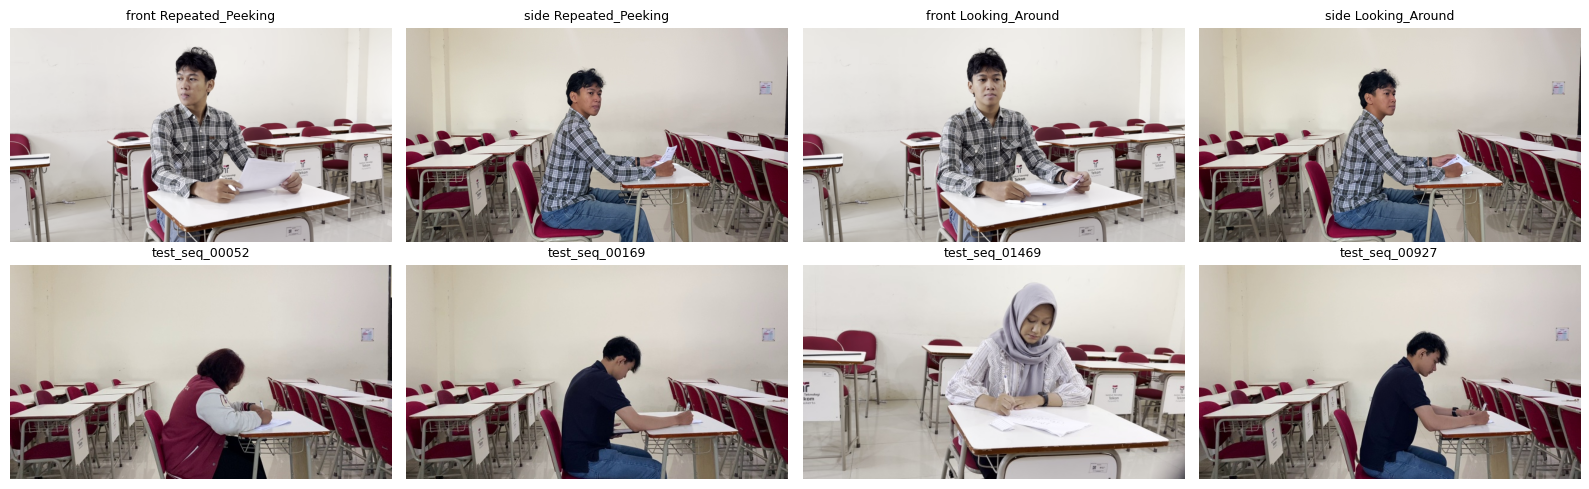

In [9]:
def middle_frame(path):
    cap = cv2.VideoCapture(path)
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) // 2)
    _, frame = cap.read()
    cap.release()
    return cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

examples = train_videos[(train_videos["subject"] == train_videos["subject"].min())
                        & train_videos["behavior"].isin(["Looking_Around", "Repeated_Peeking"])]
fig, ax = plt.subplots(2, 4, figsize=(16, 5))
for a, (_, r) in zip(ax[0], examples.iterrows()):
    a.imshow(middle_frame(r["path"])); a.set_title(f"{r['angle']} {r['behavior']}", fontsize=9)
for a, p in zip(ax[1], test_seqs["path"].sample(4, random_state=SEED)):
    a.imshow(cv2.cvtColor(cv2.imread(sorted(glob.glob(f"{p}/*.jpg"))[0]), cv2.COLOR_BGR2RGB)); a.set_title(os.path.basename(p), fontsize=9)
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

# Preprocessing

### Penyamaan frame train dan test
Setiap frame train di-resize ke 640 x 360 lalu di-encode dan di-decode JPEG, sama seperti frame test. Setelah itu semua frame (train dan test) diubah ke grayscale ukuran kecil 160 x 90 untuk fitur gerakan, dan 128 x 64 untuk fitur HOG.

In [10]:
TEST_W, TEST_H = 640, 360
WORK_W, WORK_H = 160, 90
HOG_W, HOG_H = 128, 64
JPEG_QUALITY = 90
CLIP_LEN = 30
TRAIN_STRIDE = 15   # klip train overlap setengah detik

def to_gray(frame_bgr, from_video):
    if from_video:
        frame_bgr = cv2.resize(frame_bgr, (TEST_W, TEST_H), interpolation=cv2.INTER_AREA)
        _, buf = cv2.imencode(".jpg", frame_bgr, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
        frame_bgr = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    return cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)

def read_video(path):
    cap, frames = cv2.VideoCapture(path), []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        frames.append(to_gray(f, from_video=True))
    cap.release()
    return frames

def read_sequence(folder):
    return [to_gray(cv2.imread(p), from_video=False) for p in sorted(glob.glob(f"{folder}/*.jpg"))]

### Pemotongan klip
Video train dipotong menjadi klip 30 frame dengan stride 15 frame. Semua klip dari satu video punya label, subjek, dan perilaku yang sama dengan videonya.

In [11]:
def clip_starts(n_frames, stride):
    return list(range(0, max(n_frames - CLIP_LEN, 0) + 1, stride))

n_clips = train_videos["n_frames"].map(lambda n: len(clip_starts(n, TRAIN_STRIDE)))
print(f"perkiraan jumlah klip train: {n_clips.sum()} | per video: {n_clips.min()}-{n_clips.max()}")

perkiraan jumlah klip train: 12717 | per video: 26-36


# Feature Engineering

### Fitur frame difference
Selisih absolut antar frame berurutan menunjukkan bagian gambar yang bergerak:
- md_mean, md_std, md_max, md_p90: statistik energi gerakan per frame selama 1 detik.
- md_half_ratio: energi gerakan paruh kedua dibanding paruh pertama.
- mg_mean_{r}_{c}, mg_std_{r}_{c}: rata-rata dan standar deviasi gerakan di grid 6 x 8, untuk melihat bagian tubuh mana yang bergerak (kepala, tangan, bawah meja).

In [12]:
GRID_R, GRID_C = 6, 8

def grid_mean(img, rows, cols):
    h, w = img.shape[-2:]
    img = img[..., : h // rows * rows, : w // cols * cols]
    return img.reshape(*img.shape[:-2], rows, h // rows, cols, w // cols).mean(axis=(-3, -1))

def diff_features(small):
    diff = np.abs(np.diff(small, axis=0))                  # (29, H, W)
    energy = diff.mean(axis=(1, 2))
    half = len(energy) // 2
    feats = dict(md_mean=energy.mean(), md_std=energy.std(), md_max=energy.max(),
                 md_p90=np.percentile(energy, 90),
                 md_half_ratio=(energy[half:].mean() + 1e-6) / (energy[:half].mean() + 1e-6))
    g = grid_mean(diff, GRID_R, GRID_C)                     # (29, R, C)
    for name, arr in (("mean", g.mean(0)), ("std", g.std(0))):
        for r in range(GRID_R):
            for c in range(GRID_C):
                feats[f"mg_{name}_{r}_{c}"] = arr[r, c]
    return feats

### Fitur optical flow
Optical flow Farneback memberi arah gerakan, bukan hanya besarnya:
- of_dx, of_dy, of_mag_mean, of_mag_std, of_mag_max: arah dan besar gerakan rata-rata.
- of_ang_{k}: histogram arah gerakan (8 arah) dibobot besar gerakan, misalnya kepala menoleh ke samping vs menunduk.
- of_dx_std, of_dx_zc: variasi dan jumlah pergantian arah horizontal, untuk menangkap gerakan menoleh bolak-balik (repeated peeking).
- og_{dx|dy|mag}_{r}_{c}: arah dan besar gerakan di grid 3 x 4.

In [13]:
OF_R, OF_C, N_ANG = 3, 4, 8

def compute_flows(small_u8):
    return np.stack([
        cv2.calcOpticalFlowFarneback(small_u8[i], small_u8[i + 1], None, 0.5, 3, 9, 3, 5, 1.1, 0)
        for i in range(len(small_u8) - 1)
    ])                                                     # (29, H, W, 2)

def flow_features(flows):
    dx, dy = flows[..., 0], flows[..., 1]
    mag = np.sqrt(dx ** 2 + dy ** 2)
    ang = np.arctan2(dy, dx)
    mdx = dx.mean(axis=(1, 2))
    feats = dict(of_dx=dx.mean(), of_dy=dy.mean(), of_mag_mean=mag.mean(), of_mag_std=mag.mean(axis=(1, 2)).std(),
                 of_mag_max=mag.mean(axis=(1, 2)).max(), of_dx_std=mdx.std(),
                 of_dx_zc=int(np.sum(np.diff(np.sign(mdx - mdx.mean())) != 0)))
    hist, _ = np.histogram(ang, bins=N_ANG, range=(-np.pi, np.pi), weights=mag)
    hist = hist / (hist.sum() + 1e-6)
    for k in range(N_ANG):
        feats[f"of_ang_{k}"] = hist[k]
    for name, arr in (("dx", dx), ("dy", dy), ("mag", mag)):
        g = grid_mean(arr, OF_R, OF_C).mean(0)
        for r in range(OF_R):
            for c in range(OF_C):
                feats[f"og_{name}_{r}_{c}"] = g[r, c]
    return feats

### Fitur HOG
HOG dari frame rata-rata klip menggambarkan postur secara kasar (kepala tegak atau menunduk, posisi tangan). Fitur ini ikut mengenali subjek atau angle. Pada validasi per subjek, HOG menurunkan CV, jadi HOG tetap diekstrak dan di-cache tetapi tidak dipakai model baseline (lihat MODEL_USE_HOG).

In [14]:
USE_HOG = True
HOG_CELL, HOG_BINS = 16, 9

def hog(img):
    # HOG sederhana: sel 16x16, 9 bin orientasi unsigned, normalisasi L2 per blok 2x2 sel
    img = img.astype(np.float32)
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=1)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=1)
    mag = np.sqrt(gx ** 2 + gy ** 2)
    ang = np.rad2deg(np.arctan2(gy, gx)) % 180
    bins = np.minimum((ang / (180 / HOG_BINS)).astype(int), HOG_BINS - 1)
    cr, cc = img.shape[0] // HOG_CELL, img.shape[1] // HOG_CELL
    cells = np.zeros((cr, cc, HOG_BINS), np.float32)
    for b in range(HOG_BINS):
        cells[..., b] = grid_mean(np.where(bins == b, mag, 0), cr, cc)
    blocks = np.stack([cells[r : r + 2, c : c + 2].ravel() for r in range(cr - 1) for c in range(cc - 1)])
    return (blocks / (np.linalg.norm(blocks, axis=1, keepdims=True) + 1e-6)).ravel()

def hog_features(clip_gray):
    mean_frame = np.mean(clip_gray, axis=0).astype(np.uint8)
    h = hog(cv2.resize(mean_frame, (HOG_W, HOG_H), interpolation=cv2.INTER_AREA))
    return {f"hog_{i}": v for i, v in enumerate(h)}

### Ekstraksi fitur
Optical flow dihitung sekali per video untuk semua pasangan frame, lalu dipotong per klip. Hasil ekstraksi disimpan di folder cache agar tidak perlu dihitung ulang.

In [15]:
def frames_to_features(frames, starts):
    small_u8 = np.stack([cv2.resize(f, (WORK_W, WORK_H), interpolation=cv2.INTER_AREA) for f in frames])
    small = small_u8.astype(np.float32) / 255.0
    flows = compute_flows(small_u8)
    rows = []
    for s in starts:
        feats = {"start": s}
        feats.update(diff_features(small[s : s + CLIP_LEN]))
        feats.update(flow_features(flows[s : s + CLIP_LEN - 1]))
        if USE_HOG:
            feats.update(hog_features(frames[s : s + CLIP_LEN]))
        rows.append(feats)
    return rows

def extract_video(row):
    frames = read_video(row["path"])
    rows = frames_to_features(frames, clip_starts(len(frames), TRAIN_STRIDE))
    for r in rows:
        r.update(subject=row["subject"], label=row["label"], angle=row["angle"], behavior=row["behavior"],
                 video=os.path.basename(os.path.dirname(row["path"])) + "/" + os.path.basename(row["path"]))
    return rows

def extract_sequence(seq_id, folder):
    frames = read_sequence(folder)
    rows = frames_to_features(frames, [0])
    rows[0]["id"] = seq_id
    return rows[0]

TRAIN_CACHE = f"{CACHE_DIR}/train_feat_s{TRAIN_STRIDE}_hog{int(USE_HOG)}.pkl"
TEST_CACHE = f"{CACHE_DIR}/test_feat_hog{int(USE_HOG)}.pkl"

t0 = time.time()
if os.path.exists(TRAIN_CACHE):
    train_feat = pd.read_pickle(TRAIN_CACHE)
else:
    out = Parallel(n_jobs=-1)(delayed(extract_video)(r) for r in train_videos.to_dict("records"))
    train_feat = pd.DataFrame([r for rows in out for r in rows])
    train_feat.to_pickle(TRAIN_CACHE)
print(f"train_feat: {train_feat.shape} ({time.time() - t0:.0f}s)")

t0 = time.time()
if os.path.exists(TEST_CACHE):
    test_feat = pd.read_pickle(TEST_CACHE)
else:
    test_feat = pd.DataFrame(Parallel(n_jobs=-1)(
        delayed(extract_sequence)(i, p) for i, p in zip(test_seqs["id"], test_seqs["path"])))
    test_feat.to_pickle(TEST_CACHE)
print(f"test_feat: {test_feat.shape} ({time.time() - t0:.0f}s)")

train_feat: (12717, 914) (0s)
test_feat: (1515, 910) (0s)


### Distribusi fitur gerakan train vs test
Mengecek apakah fitur gerakan klip train (hasil potong video) sebanding dengan sequence test.

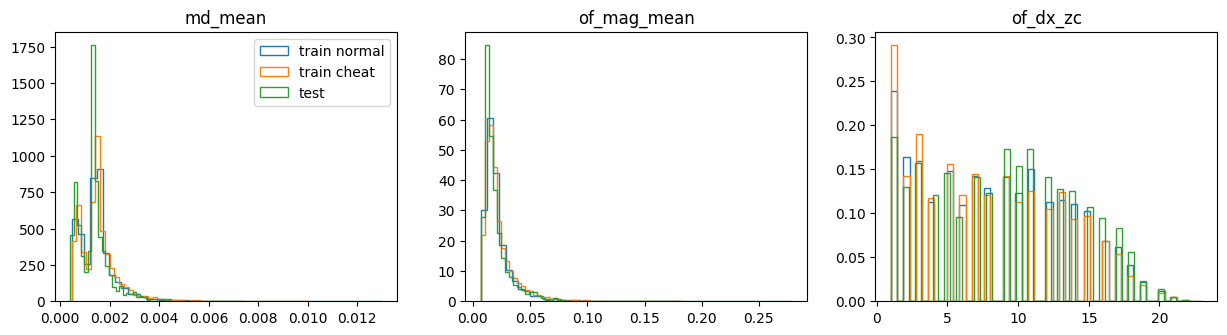

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, col in zip(ax, ["md_mean", "of_mag_mean", "of_dx_zc"]):
    for name, df in (("train normal", train_feat[train_feat["label"] == 0]),
                     ("train cheat", train_feat[train_feat["label"] == 1]), ("test", test_feat)):
        a.hist(df[col], bins=50, density=True, histtype="step", label=name)
    a.set_title(col)
ax[0].legend()
plt.show()

# Classifier Models

### Setup parameter dan validasi
Validasi memakai StratifiedGroupKFold berdasarkan subjek supaya klip dari subjek validasi tidak pernah dilihat saat training. Ini penting karena klip dari video yang sama sangat mirip, dan subjek test kemungkinan berbeda dari train.

In [17]:
META_COLS = ["start", "subject", "label", "angle", "behavior", "video", "id"]
MODEL_USE_HOG = False   # HOG membuat model menghafal subjek: CV turun dari 0.584 ke 0.513
FEATURES = [c for c in train_feat.columns if c not in META_COLS and (MODEL_USE_HOG or not c.startswith("hog_"))]
N_FOLDS = 5
LGBM_PARAMS = dict(
    objective="binary", n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=30,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=1.0, random_state=SEED,
    deterministic=True, force_row_wise=True, verbose=-1,
)

def f1_macro(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

X, y, groups = train_feat[FEATURES], train_feat["label"], train_feat["subject"]
print(f"n features: {len(FEATURES)} | n clips: {len(X)} | cheat share: {y.mean():.3f}")

n features: 152 | n clips: 12717 | cheat share: 0.503


### LGBM Classifier

In [18]:
oof = np.zeros(len(train_feat))
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
for fold, (tr_idx, va_idx) in enumerate(sgkf.split(X, y, groups)):
    model = LGBMClassifier(**LGBM_PARAMS).fit(X.iloc[tr_idx], y.iloc[tr_idx])
    oof[va_idx] = model.predict_proba(X.iloc[va_idx])[:, 1]
    print(f"fold {fold}: subjects={sorted(groups.iloc[va_idx].unique())} "
          f"F1-macro={f1_macro(y.iloc[va_idx], oof[va_idx] > 0.5):.4f}")

train_feat["oof"] = oof
print(f"CV F1-macro (threshold 0.5): {f1_macro(y, oof > 0.5):.4f}")

fold 0: subjects=[np.int64(13), np.int64(14), np.int64(22), np.int64(24), np.int64(25)] F1-macro=0.6412


fold 1: subjects=[np.int64(2), np.int64(3), np.int64(9), np.int64(10), np.int64(17)] F1-macro=0.5851


fold 2: subjects=[np.int64(1), np.int64(7), np.int64(8), np.int64(11), np.int64(20), np.int64(26)] F1-macro=0.5734


fold 3: subjects=[np.int64(6), np.int64(12), np.int64(15), np.int64(18), np.int64(23)] F1-macro=0.4975


fold 4: subjects=[np.int64(4), np.int64(5), np.int64(16), np.int64(19), np.int64(21)] F1-macro=0.5680
CV F1-macro (threshold 0.5): 0.5811


### Tuning threshold
F1-Macro memberi bobot sama pada kedua kelas, jadi threshold dicari dari prediksi OOF.

best threshold: 0.50 | CV F1-macro: 0.5811


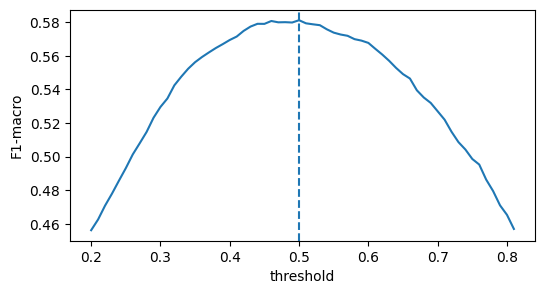

In [19]:
thresholds = np.arange(0.2, 0.81, 0.01)
scores = [f1_macro(y, oof > t) for t in thresholds]
BEST_THR = float(thresholds[int(np.argmax(scores))])
print(f"best threshold: {BEST_THR:.2f} | CV F1-macro: {max(scores):.4f}")
plt.figure(figsize=(6, 3)); plt.plot(thresholds, scores); plt.axvline(BEST_THR, ls="--")
plt.xlabel("threshold"); plt.ylabel("F1-macro"); plt.show()

### Analisis error per perilaku dan angle
Melihat perilaku mana yang paling sering salah, terutama pasangan yang mirip (Looking Around vs Repeated Peeking, Checking vs Using Smartwatch).

In [20]:
train_feat["pred"] = (train_feat["oof"] > BEST_THR).astype(int)
train_feat["correct"] = train_feat["pred"] == train_feat["label"]
print(confusion_matrix(y, train_feat["pred"]))
print(train_feat.pivot_table(index=["label", "behavior"], columns="angle", values="correct", aggfunc="mean").round(3))
print("\nakurasi per subjek:")
print(train_feat.groupby("subject")["correct"].mean().sort_values().round(3).head(8).to_dict())

[[3675 2641]
 [2686 3715]]
angle                         front   side
label behavior                            
0     Checking_Smartwatch     0.551  0.616
      Looking_Around          0.584  0.609
      Thinking                0.571  0.644
      Writing_Answers         0.495  0.579
1     Looking_Under_the_Desk  0.771  0.615
      Reading_Hidden_Notes    0.628  0.527
      Repeated_Peeking        0.503  0.493
      Using_Smartwatch        0.665  0.449

akurasi per subjek:
{6: 0.429, 15: 0.457, 16: 0.499, 3: 0.519, 18: 0.519, 24: 0.531, 17: 0.537, 4: 0.553}


### Final model
Melatih ulang LGBM di seluruh data train dengan parameter yang sama seperti saat CV.

In [21]:
final_model = LGBMClassifier(**LGBM_PARAMS).fit(X, y)
joblib.dump(final_model, "models/baseline_model.pkl")
print("n_estimators =", LGBM_PARAMS["n_estimators"])

n_estimators = 400


### Feature Importance for LGBM

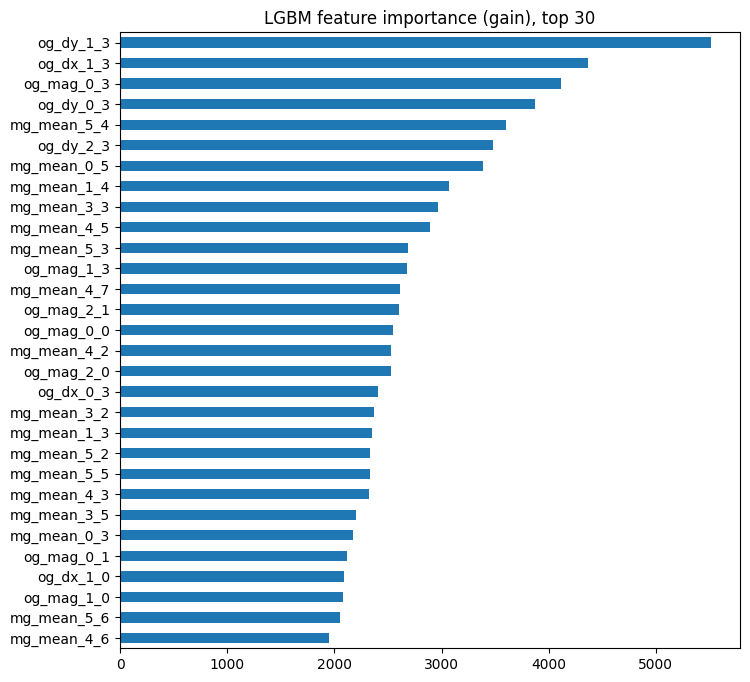

mg    0.637
og    0.324
of    0.035
md    0.003
dtype: float64

In [22]:
importance = pd.Series(final_model.booster_.feature_importance(importance_type="gain"), index=FEATURES)
importance.sort_values().tail(30).plot(kind="barh", figsize=(8, 8), title="LGBM feature importance (gain), top 30")
plt.show()
group_imp = importance.groupby(importance.index.str.split("_").str[0]).sum()
(group_imp / group_imp.sum()).round(3).sort_values(ascending=False)

# Postprocessing

### Threshold
Probabilitas test diubah menjadi label dengan threshold terbaik dari OOF. Distribusi prediksi dicek supaya tidak condong ke satu kelas.

threshold 0.50 | cheat share test: 0.564


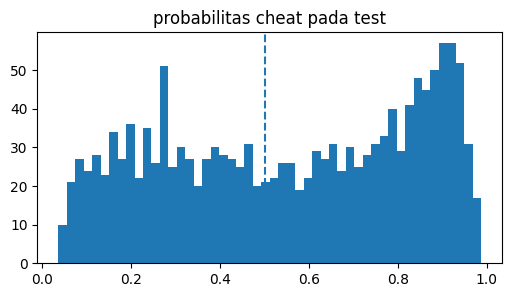

In [23]:
test_feat["prob"] = final_model.predict_proba(test_feat[FEATURES])[:, 1]
test_feat["label"] = (test_feat["prob"] > BEST_THR).astype(int)
print(f"threshold {BEST_THR:.2f} | cheat share test: {test_feat['label'].mean():.3f}")
plt.figure(figsize=(6, 3)); plt.hist(test_feat["prob"], bins=50); plt.axvline(BEST_THR, ls="--")
plt.title("probabilitas cheat pada test"); plt.show()

# Submission

In [24]:
submission = sample_sub[["id"]].merge(test_feat[["id", "label"]], on="id", how="left")
assert len(submission) == len(sample_sub) and submission["label"].notna().all()
submission["label"] = submission["label"].astype(int)
submission.to_csv("submissions/submission_baseline.csv", index=False)
submission["label"].value_counts()

label
1    854
0    661
Name: count, dtype: int64